# Churn Prediction — Exploratory Analysis

Telco customer churn dataset. Trying to predict which customers will leave.

**Run cells top to bottom. Do not skip cells.**

## 1. Data Loading

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# TODO: make this configurable
df = pd.read_csv('../data/telco_churn.csv')

print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [4]:
# TotalCharges should be numeric but has blanks — known issue with this dataset
print('TotalCharges dtype:', df['TotalCharges'].dtype)
print('Blank TotalCharges rows:', (df['TotalCharges'].str.strip() == '').sum())

TotalCharges dtype: object
Blank TotalCharges rows: 11


## 2. Exploratory Data Analysis

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


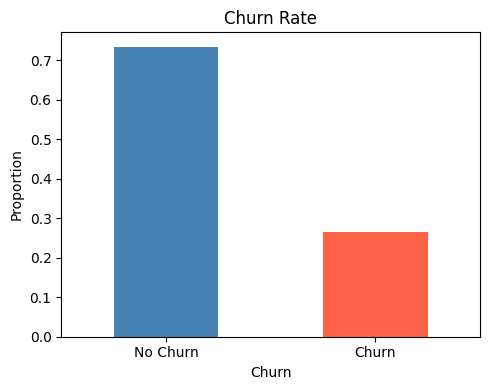

In [5]:
# Overall churn rate
churn_rate = df['Churn'].value_counts(normalize=True)
print(churn_rate)

fig, ax = plt.subplots(figsize=(5, 4))
churn_rate.plot(kind='bar', ax=ax, color=['steelblue', 'tomato'])
ax.set_title('Churn Rate')
ax.set_ylabel('Proportion')
ax.set_xticklabels(['No Churn', 'Churn'], rotation=0)
plt.tight_layout()
plt.show()

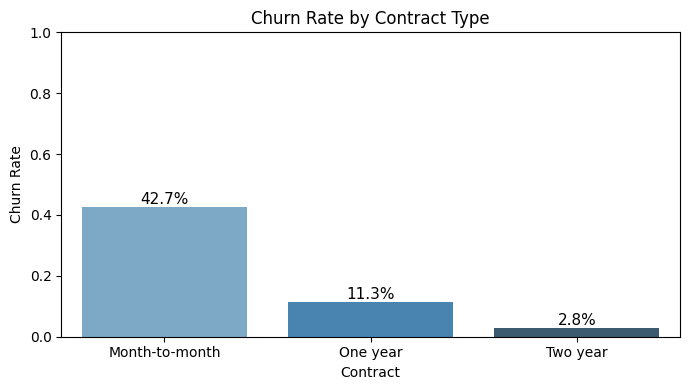

In [6]:
# Churn rate by contract type
# Month-to-month customers churn way more — makes sense
contract_churn = df.groupby('Contract')['Churn'].apply(
    lambda x: (x == 'Yes').mean()
).reset_index()
contract_churn.columns = ['Contract', 'ChurnRate']

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=contract_churn, x='Contract', y='ChurnRate', ax=ax, palette='Blues_d')
ax.set_title('Churn Rate by Contract Type')
ax.set_ylabel('Churn Rate')
ax.set_ylim(0, 1)
for p in ax.patches:
    ax.annotate(f'{p.get_height():.1%}', (p.get_x() + p.get_width() / 2, p.get_height() + 0.01),
                ha='center', fontsize=11)
plt.tight_layout()
plt.show()

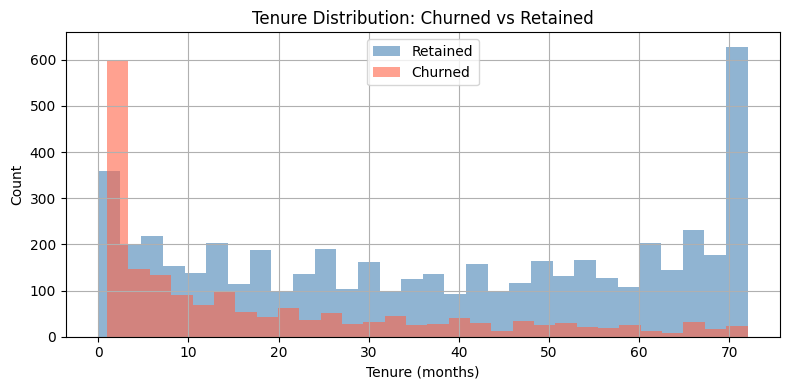

In [7]:
# Tenure distribution — churned vs retained
fig, ax = plt.subplots(figsize=(8, 4))
df[df['Churn'] == 'No']['tenure'].hist(ax=ax, bins=30, alpha=0.6, label='Retained', color='steelblue')
df[df['Churn'] == 'Yes']['tenure'].hist(ax=ax, bins=30, alpha=0.6, label='Churned', color='tomato')
ax.set_title('Tenure Distribution: Churned vs Retained')
ax.set_xlabel('Tenure (months)')
ax.set_ylabel('Count')
ax.legend()
plt.tight_layout()
plt.show()

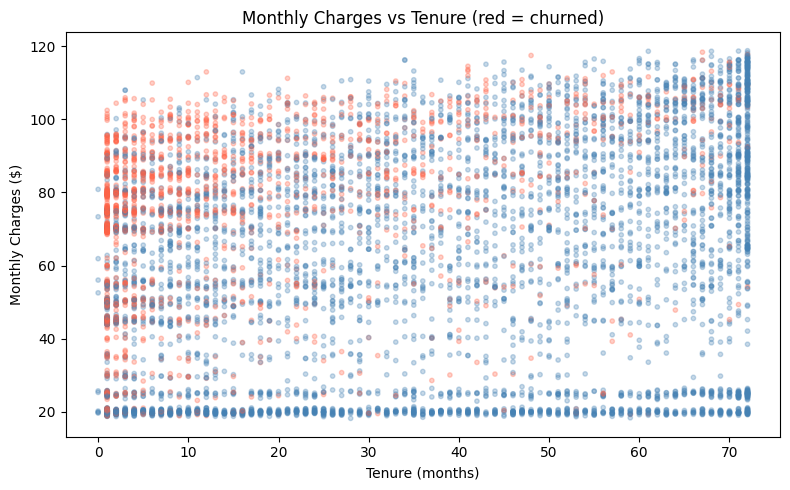

In [8]:
# Monthly charges vs tenure coloured by churn
fig, ax = plt.subplots(figsize=(8, 5))
colors = df['Churn'].map({'Yes': 'tomato', 'No': 'steelblue'})
ax.scatter(df['tenure'], df['MonthlyCharges'], c=colors, alpha=0.3, s=10)
ax.set_xlabel('Tenure (months)')
ax.set_ylabel('Monthly Charges ($)')
ax.set_title('Monthly Charges vs Tenure (red = churned)')
plt.tight_layout()
plt.show()

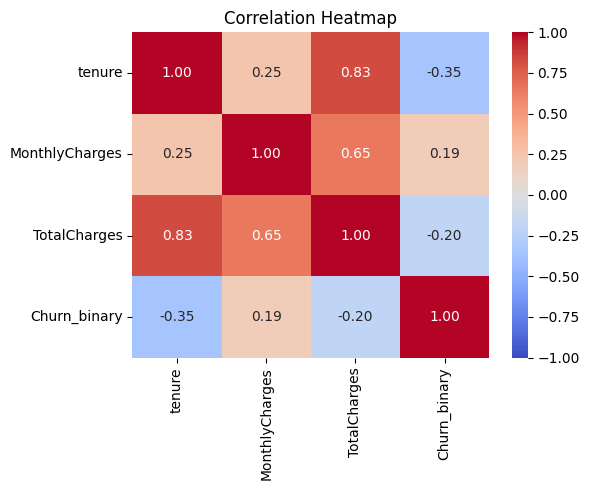

In [9]:
# Correlation heatmap — numeric columns only
# Need to fix TotalCharges first before this cell works
df_numeric = df.copy()
df_numeric['TotalCharges'] = pd.to_numeric(df_numeric['TotalCharges'], errors='coerce')
df_numeric['Churn_binary'] = (df_numeric['Churn'] == 'Yes').astype(int)

corr = df_numeric[['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn_binary']].corr()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', ax=ax, vmin=-1, vmax=1)
ax.set_title('Correlation Heatmap')
plt.tight_layout()
plt.show()

## 3. Preprocessing

Everything inline — no helper functions yet.

In [10]:
df_clean = df.copy()

# Drop customer ID — not a feature
df_clean = df_clean.drop(columns=['customerID'])

# Fix TotalCharges blanks — customers with tenure=0 have blank TotalCharges
df_clean['TotalCharges'] = pd.to_numeric(df_clean['TotalCharges'], errors='coerce')
df_clean['TotalCharges'] = df_clean['TotalCharges'].fillna(0.0)

# Binary target
df_clean['Churn'] = (df_clean['Churn'] == 'Yes').astype(int)

print(df_clean.shape)
df_clean.head()

(7043, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [11]:
# One-hot encode all object columns (except target)
cat_cols = df_clean.select_dtypes(include='object').columns.tolist()
print('Encoding:', cat_cols)

df_encoded = pd.get_dummies(df_clean, columns=cat_cols, drop_first=True)
print(df_encoded.shape)
df_encoded.head()

Encoding: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
(7043, 31)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,False,True,False,False,True,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,0,True,False,False,True,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,1,True,False,False,True,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,0,True,False,False,False,True,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,1,False,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False


In [12]:
from sklearn.preprocessing import StandardScaler

# Scale numeric features — hardcoded column list
scale_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

scaler = StandardScaler()
df_encoded[scale_cols] = scaler.fit_transform(df_encoded[scale_cols])

df_encoded[scale_cols].describe().round(2)

,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,-0.00,-0.00,-0.00
std,1.00,1.00,1.00
min,-1.32,-1.55,-1.01
25%,-0.95,-0.97,-0.83
50%,-0.14,0.19,-0.39
75%,0.92,0.83,0.66
max,1.61,1.79,2.83


## 4. Model Training

In [14]:
from sklearn.model_selection import train_test_split

X = df_encoded.drop(columns=['Churn'])
y = df_encoded['Churn']

# 80/20 split — same seed every time so results are reproducible (sort of)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print('Train size:', X_train.shape)
print('Test size: ', X_test.shape)

Train size: (5634, 30)
Test size:  (1409, 30)


In [15]:
from sklearn.ensemble import RandomForestClassifier

# Hardcoded hyperparameters — no tuning yet
model = RandomForestClassifier(
    n_estimators=100,
    max_depth=8,
    random_state=42,
    n_jobs=-1
)
model.fit(X_train, y_train)
print('Done training.')

Done training.


## 5. Evaluation

Nothing is saved to disk — rerun the notebook to reproduce results.

In [16]:
from sklearn.metrics import roc_auc_score, classification_report

y_prob = model.predict_proba(X_test)[:, 1]
y_pred = model.predict(X_test)

roc_auc = roc_auc_score(y_test, y_prob)
print(f'ROC-AUC: {roc_auc:.4f}')
print()
print(classification_report(y_test, y_pred, target_names=['Retained', 'Churned']))

ROC-AUC: 0.8645

              precision    recall  f1-score   support

    Retained       0.83      0.92      0.87      1036
     Churned       0.69      0.49      0.57       373

    accuracy                           0.81      1409
   macro avg       0.76      0.70      0.72      1409
weighted avg       0.79      0.81      0.79      1409



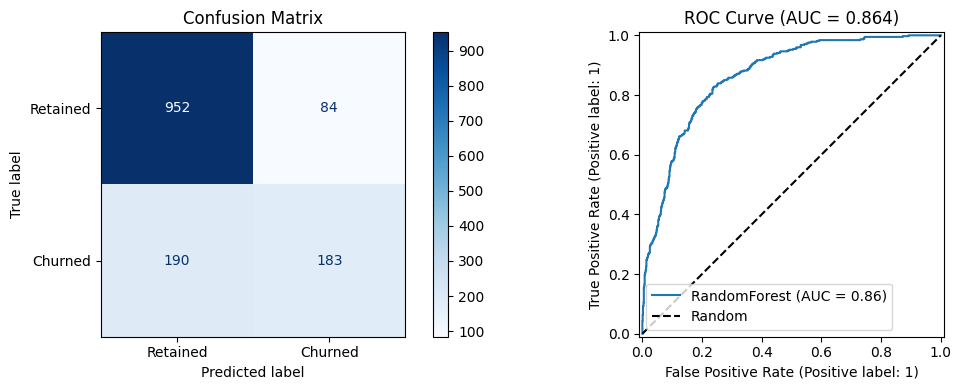

In [18]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=['Retained', 'Churned'],
    cmap='Blues', ax=axes[0]
)
axes[0].set_title('Confusion Matrix')

RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[1], name='RandomForest')
axes[1].set_title(f'ROC Curve (AUC = {roc_auc:.3f})')
axes[1].plot([0, 1], [0, 1], 'k--', label='Random')
axes[1].legend()

plt.tight_layout()
plt.show()

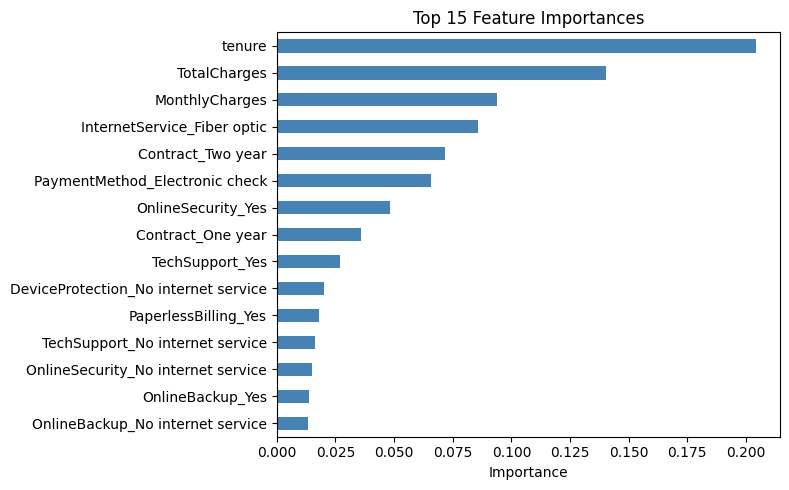

In [17]:
# Top features — useful to know before we move to train.py
importances = pd.Series(model.feature_importances_, index=X.columns)
top_features = importances.nlargest(15)

fig, ax = plt.subplots(figsize=(8, 5))
top_features.sort_values().plot(kind='barh', ax=ax, color='steelblue')
ax.set_title('Top 15 Feature Importances')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()

---
## What's broken here (intentionally)

- `scaler` is fit on the full column before the train/test split — **data leakage**
- Hardcoded file path `../data/telco_churn.csv` — breaks if you move the notebook
- The fitted `model` and `scaler` objects live only in memory — nothing is saved
- Re-running produces identical results only if cells are run in order
- Preprocessing logic is duplicated: any serving code would have to copy-paste it

These are the exact problems that `src/train.py` + `src/preprocess.py` (Step 2) will fix.